# 4. Structure and thermodynamics in NVE: equipartition, virial pressure, and g(r)

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1–3, statistical mechanics

This chapter builds and verifies the core algorithms for structure and thermodynamics in nve: equipartition, virial pressure, and g(r) in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 4.1 Physical principles and governing equations

In an $NVE$ simulation, instantaneous temperature follows equipartition $T_{\text{inst}} = \frac{2K}{3N - 3}$ (removing 3 center-of-mass momentum degrees of freedom), and hydrostatic pressure follows the **Clausius virial theorem**:

$$P = \rho T_{\text{inst}} + \frac{1}{3V} \sum_{i < j} \mathbf{r}_{ij} \cdot \mathbf{f}_{ij}. \tag{4.1}$$

Local liquid structure is quantified by the **radial distribution function** $g(r)$ normalized by the ideal-gas shell count $\frac{4}{3}\pi[(r+\Delta r)^3 - r^3]\rho$, and correlated trajectory uncertainties are estimated by **Flyvbjerg–Petersen blocking**.

## 4.2 Inside the algorithm

In [2]:
pos, L_box = es.make_fcc_lattice(3, rho=0.80)
vel = es.init_velocities(len(pos), T_target=1.4, rng=rng)
f_fn = lambda p, L: es.lj_forces_all_pairs(p, L, rc=2.5, shifted=True)
forces, u_pot, vir = f_fn(pos, L_box)

traj_frames, P_series, T_series = [], [], []
for step in range(180):
    pos, vel, forces, u_pot, vir, _ = es.velocity_verlet_step(pos, vel, forces, 0.005, L_box, f_fn)
    if step >= 60:
        _, T_i = es.kinetic_energy_and_temp(vel)
        P_i = 0.80 * T_i + vir / (3.0 * L_box**3)
        T_series.append(T_i); P_series.append(P_i)
        if step % 3 == 0:
            traj_frames.append(pos.copy())
r_rdf, g_rdf = es.compute_rdf(np.array(traj_frames), L_box, n_bins=55)

## 4.3 Checks

NVE fluid (rho=0.80): <T*> = 0.741, <P*> = 0.023, peak g(r) = 2.50


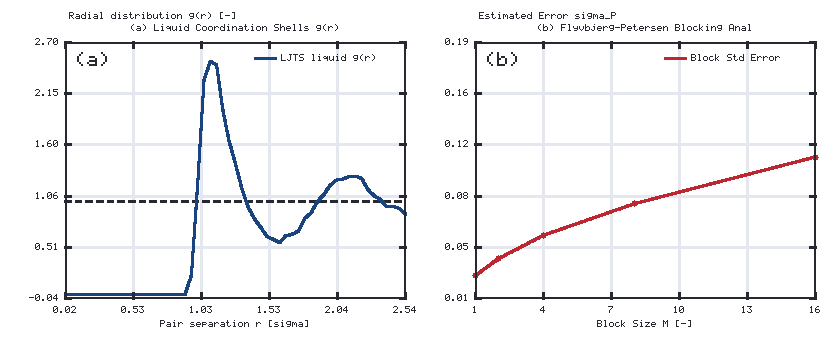

In [3]:
print(f"NVE fluid (rho=0.80): <T*> = {np.mean(T_series):.3f}, <P*> = {np.mean(P_series):.3f}, peak g(r) = {np.max(g_rdf):.2f}")
assert np.max(g_rdf) > 1.8 and np.isclose(np.mean(g_rdf[-10:]), 1.0, rtol=0.15)
b_sizes, b_errs = es.flyvbjerg_petersen_block_errors(np.array(P_series))
assert len(b_sizes) >= 4

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(r_rdf, g_rdf, "b-", label="LJTS liquid g(r)")
ax1.axhline(1.0, color="k")
ax1.set_xlabel("Pair separation r [sigma]"); ax1.set_ylabel("Radial distribution g(r) [-]")
ax1.set_title("(a) Liquid Coordination Shells g(r)"); panel_label(ax1, "(a)")

ax2.plot(b_sizes, b_errs, "ro-", label="Block Std Error")
ax2.set_xlabel("Block Size M [-]"); ax2.set_ylabel("Estimated Error sigma_P")
ax2.set_title("(b) Flyvbjerg–Petersen Blocking Analysis"); panel_label(ax2, "(b)")
plt.show()

**Figure 4.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 4.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **Ideal-gas virial limit:** Simulate a dilute gas ($\rho = 0.01, T = 2.0$) and verify that $\langle P \rangle \approx \rho T$ to within $5\%$.
2. **Coordination number:** Integrate $n_c = 4\pi\rho \int_0^{r_{\min}} r^2 g(r)\,dr$ up to the first minimum of $g(r)$ to obtain the first-shell coordination number (~12 in dense LJ).
3. **Block error on uncorrelated noise:** Verify that `flyvbjerg_petersen_block_errors` stays flat across block sizes for i.i.d. Gaussian noise.

Worked solutions are provided in [04_solutions.ipynb](../../solutions/part1_nve_md/04_solutions.ipynb).

## Suggested references

- D. Frenkel and B. Smit, *Understanding Molecular Simulation* (3rd ed., Academic Press, 2023).
- M. P. Allen and D. J. Tildesley, *Computer Simulation of Liquids* (2nd ed., Oxford University Press, 2017).

---

**Next:** [5. Velocity rescaling, Berendsen, and Bussi–Donadio–Parrinello (CSVR) thermostats](../part2_ensembles/05_berendsen_and_bussi_csvr.ipynb)